# 117 · LeRobot (kernel: Python (lerobot)): export TableTop to the official LeRobotDataset v3.0 and load it back

In [1]:
import os, glob, json, shutil, time, numpy as np, torch, matplotlib.pyplot as plt
from lerobot.datasets.lerobot_dataset import LeRobotDataset, CODEBASE_VERSION

SRC = os.path.abspath("../data/tabletop_panda_v1")
ROOT = os.path.abspath("../data/lerobot_v3/tabletop_panda_v1")
FEATURES = {
    "observation.images.front": {"dtype": "video", "shape": (128, 128, 3), "names": ["height", "width", "channels"]},
    "observation.images.wrist": {"dtype": "video", "shape": (128, 128, 3), "names": ["height", "width", "channels"]},
    "observation.state": {"dtype": "float32", "shape": (8,), "names": ["ee_x", "ee_y", "ee_z", "qw", "qx", "qy", "qz", "gripper_width"]},
    "action": {"dtype": "float32", "shape": (7,), "names": ["dx", "dy", "dz", "droll", "dpitch", "dyaw", "grip"]},
}

def export(src, root):
    shutil.rmtree(root, ignore_errors=True)
    ds = LeRobotDataset.create(repo_id="local/tabletop_panda_v1", fps=10, features=FEATURES, root=root, robot_type="franka_panda", use_videos=True, vcodec="h264")
    for path in sorted(glob.glob(f"{src}/episode_*.npz")):
        z = np.load(path)
        for t in range(len(z["action"])):
            ds.add_frame({"observation.images.front": z["front"][t], "observation.images.wrist": z["wrist"][t],
                          "observation.state": z["state"][t], "action": z["action"][t], "task": str(z["instruction"])})
        ds.save_episode()
    ds.finalize()
    return ds

~/.lr/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print("LeRobot dataset codebase version:", CODEBASE_VERSION)
if not os.path.exists(f"{ROOT}/meta/info.json"):
    t0 = time.time(); export(SRC, ROOT); print(f"exported in {time.time() - t0:.0f}s")
info = json.load(open(f"{ROOT}/meta/info.json"))
print({k: info[k] for k in ["codebase_version", "robot_type", "total_episodes", "total_frames", "total_tasks", "fps"]})
for r, _, fs in os.walk(ROOT):
    if fs:
        print(f"  {r[len(ROOT):] or '/'}: {fs[:3]}{' ...' if len(fs) > 3 else ''}")

LeRobot dataset codebase version: v3.0
{'codebase_version': 'v3.0', 'robot_type': 'franka_panda', 'total_episodes': 200, 'total_frames': 8420, 'total_tasks': 12, 'fps': 10}
  /data/chunk-000: ['file-000.parquet']
  /meta: ['tasks.parquet', 'stats.json', 'info.json']
  /meta/episodes/chunk-000: ['file-000.parquet']
  /videos/observation.images.front/chunk-000: ['file-000.mp4']
  /videos/observation.images.wrist/chunk-000: ['file-000.mp4']


{'observation.images.front': (2, 3, 128, 128), 'observation.images.wrist': (3, 128, 128), 'observation.state': (8,), 'action': (16, 7), 'timestamp': (), 'frame_index': (), 'episode_index': (), 'index': (), 'task_index': (), 'action_is_pad': (16,), 'observation.images.front_is_pad': (2,), 'task': 'stack the blue cube on the green cube'}
action_is_pad: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


~/.lr/lib/python3.11/site-packages/torchvision/io/_video_deprecation_warning.py:9: UserWarning: The video decoding and encoding capabilities of torchvision are deprecated from version 0.22 and will be removed in version 0.24. We recommend that you migrate to TorchCodec, where we'll consolidate the future decoding/encoding capabilities of PyTorch: https://github.com/pytorch/torchcodec
  warnings.warn(


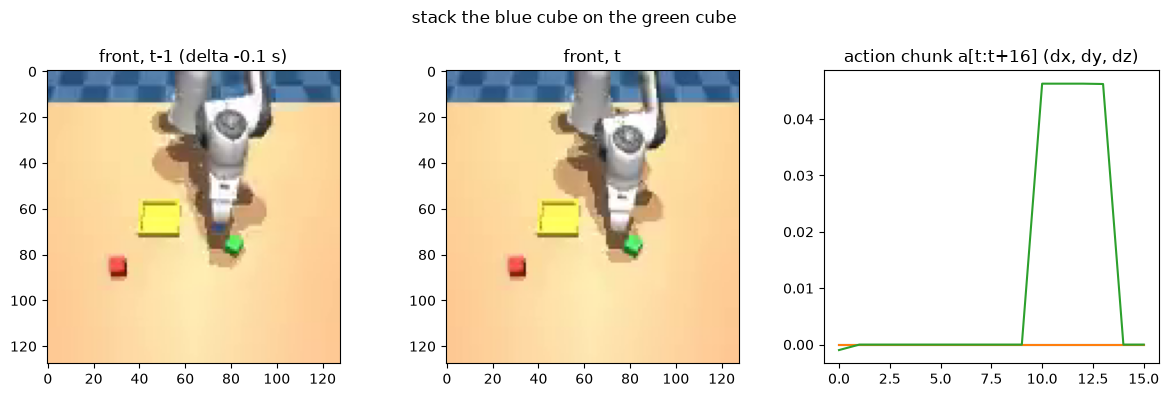

In [3]:
H = 16
# video_backend="pyav": PyAV bundles its own FFmpeg. The default (torchcodec) needs system FFmpeg 4-8 shared libraries,
# which many machines (and Colab images) don't have: "Could not load libtorchcodec ... libavutil.so" means exactly that.
ds = LeRobotDataset("local/tabletop_panda_v1", root=ROOT, delta_timestamps={"action": [i / 10 for i in range(H)], "observation.images.front": [-0.1, 0.0]},
                    video_backend="pyav")
s = ds[123]
print({k: (tuple(v.shape) if hasattr(v, "shape") else v) for k, v in s.items()})
print("action_is_pad:", s["action_is_pad"].int().tolist())
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(s["observation.images.front"][0].permute(1, 2, 0)); ax[0].set_title("front, t-1 (delta -0.1 s)")
ax[1].imshow(s["observation.images.front"][1].permute(1, 2, 0)); ax[1].set_title("front, t")
ax[2].plot(s["action"][:, :3]); ax[2].set_title("action chunk a[t:t+16] (dx, dy, dz)")
plt.suptitle(s["task"]); plt.tight_layout(); plt.show()

In [4]:
stats = ds.meta.stats
print("action mean:", np.round(np.array(stats["action"]["mean"]), 4))
print("action std :", np.round(np.array(stats["action"]["std"]), 4))
print("tasks:", list(ds.meta.tasks.index)[:5], "...")
dl = torch.utils.data.DataLoader(ds, batch_size=32, shuffle=True, num_workers=0)
b = next(iter(dl))
print("batch:", {k: (tuple(v.shape) if hasattr(v, "shape") else type(v).__name__) for k, v in b.items()})
print("To share: ds.push_to_hub()  (requires `huggingface-cli login`); training a LeRobot policy: lerobot-train --dataset.repo_id=local/tabletop_panda_v1 --dataset.root=" + ROOT)

action mean: [-1.200e-03  2.000e-04 -1.030e-02  0.000e+00  0.000e+00 -4.000e-04
  5.524e-01]
action std : [0.008  0.0128 0.0239 0.     0.     0.0599 0.4972]
tasks: ['stack the green cube on the blue cube', 'put the blue cube in the yellow tray', 'stack the blue cube on the green cube', 'stack the blue cube on the red cube', 'put the green cube in the yellow tray'] ...


batch: {'observation.images.front': (32, 2, 3, 128, 128), 'observation.images.wrist': (32, 3, 128, 128), 'observation.state': (32, 8), 'action': (32, 16, 7), 'timestamp': (32,), 'frame_index': (32,), 'episode_index': (32,), 'index': (32,), 'task_index': (32,), 'action_is_pad': (32, 16), 'observation.images.front_is_pad': (32, 2), 'task': 'list'}
To share: ds.push_to_hub()  (requires `huggingface-cli login`); training a LeRobot policy: lerobot-train --dataset.repo_id=local/tabletop_panda_v1 --dataset.root=data/lerobot_v3/tabletop_panda_v1
